# Lightweight Object Detectors for Field-Crop / Weed-Aware Detection on AgriAISeg
**Experimental notebook**: trains and evaluates 7 light SOTA detectors under *identical* conditions and reports accuracy, efficiency, per-class results, robustness to illumination/blur/noise, and a final model recommendation.

**Pipeline (run top to bottom):**
0. Install  1. Config  2. Dataset download  3. Dataset analysis  4. Prepare YOLO yaml  5. Sample visualisation  6. Training  7. Test evaluation  8. Latency benchmark  9. Results table  10. Plots  11. Training curves  12. Per-class results  13. Composite ranking and best model  14. Qualitative predictions  15. Robustness study  16. Export everything

> Fairness: every model uses the same Ultralytics pipeline, same data, same split, same image size, same epochs, batch, optimiser, LR schedule, augmentation, seed(s), COCO-pretrained init, and no early stopping.

## 0. Install

In [1]:
!pip install -q -U ultralytics kagglehub pandas matplotlib seaborn opencv-python-headless pyyaml tqdm
import ultralytics; print("ultralytics", ultralytics.__version__)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 3.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 3.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.4/57.4 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 29.2 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 88.8 MB/s eta 0:00:00:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 90.1 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.2/61.2 MB 32.6 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.2/80.2 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 kB 5.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.


## 1. Configuration (single place to change everything)

In [2]:
import os, sys, json, time, random, shutil, glob, warnings, gc, platform
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, yaml, cv2, torch
from tqdm.auto import tqdm
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)

# ---------------- models (all nano/tiny, COCO-pretrained) ----------------
MODELS = {
    "YOLOv5n":  "yolov5nu.pt",
    "YOLOv8n":  "yolov8n.pt",
    "YOLOv9t":  "yolov9t.pt",
    "YOLOv10n": "yolov10n.pt",
    "YOLO11n":  "yolo11n.pt",
    "YOLO12n":  "yolo12n.pt",
    "YOLO26n":  "yolo26n.pt",   # needs a recent ultralytics; skipped automatically if unavailable
}

# ---------------- identical training hyper-parameters ----------------
SEEDS = [0]            # e.g. [0,1,2] to report mean +- std (3x training time)
TRAIN_KW = dict(
    imgsz=640, epochs=100, batch=16, optimizer="SGD", lr0=0.01, lrf=0.01,
    momentum=0.937, weight_decay=5e-4, warmup_epochs=3, cos_lr=False,
    patience=100,            # == epochs -> no early stopping, same #epochs for all
    close_mosaic=10, workers=4, amp=True, deterministic=True, cache=False,
    pretrained=True, mosaic=1.0, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4,
    fliplr=0.5, flipud=0.0, scale=0.5, translate=0.1,
)
EVAL_KW = dict(imgsz=TRAIN_KW["imgsz"], batch=16, conf=0.001, iou=0.6)
LAT_N, LAT_WARMUP, CPU_THREADS = 100, 20, 4     # latency benchmark settings

# composite ranking weights (must sum to 1)
RANK_W = dict(mAP50_95=0.50, cpu_fps=0.25, params_M=0.125, gflops=0.125)

DEVICE = 0 if torch.cuda.is_available() else "cpu"
WORK = Path("weed_exp"); RUNS = WORK/"runs"; EVAL = WORK/"eval"; FIGS = WORK/"figs"; RES = WORK/"results"
for d in (WORK, RUNS, EVAL, FIGS, RES): d.mkdir(parents=True, exist_ok=True)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(0)
env = dict(python=platform.python_version(), torch=torch.__version__,
           gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only",
           cpu=platform.processor(), ultralytics=ultralytics.__version__)
json.dump(dict(env=env, train=TRAIN_KW, eval=EVAL_KW, models=MODELS, seeds=SEEDS), open(RES/"experiment_config.json","w"), indent=2)
print(env)

{'python': '3.13.15', 'torch': '2.11.0+cu128', 'gpu': 'Tesla T4', 'cpu': 'x86_64', 'ultralytics': '8.4.177'}


## 2. Download dataset

In [3]:
import kagglehub
src = Path(kagglehub.dataset_download("ismailismailtijjani/agriaiseg"))
print("Downloaded to:", src)

# locate the folder that contains train/images
cands = [p.parent.parent for p in src.rglob("images") if p.parent.name in ("train",) and p.is_dir()]
assert cands, "Could not find train/images inside the dataset"
SRC_ROOT = sorted(cands, key=lambda p: len(p.parts))[0]
print("Dataset root:", SRC_ROOT)
print(sorted(os.listdir(SRC_ROOT)))

Downloaded to: /kaggle/input/datasets/ismailismailtijjani/agriaiseg
Dataset root: /kaggle/input/datasets/ismailismailtijjani/agriaiseg/AGRISEGAI/CABBAGE
['test', 'train', 'valid']


## 3. Copy to a writable folder, detect splits and class names

In [4]:
DATA = WORK/"data"
SPLIT_ALIASES = {"train": ["train"], "val": ["valid", "val", "validation"], "test": ["test"]}
SPLITS = {}
for k, names in SPLIT_ALIASES.items():
    for n in names:
        if (SRC_ROOT/n/"images").exists():
            SPLITS[k] = n; break
print("Detected splits:", SPLITS)
assert "train" in SPLITS and "val" in SPLITS, "train/valid splits are required"
if "test" not in SPLITS:
    print("WARNING: no test split found -> using validation split as test.")

for k, n in SPLITS.items():
    dst = DATA/n
    if not dst.exists():
        shutil.copytree(SRC_ROOT/n, dst)
SPLIT_DIR = {k: DATA/n for k, n in SPLITS.items()}
if "test" not in SPLIT_DIR: SPLIT_DIR["test"] = SPLIT_DIR["val"]

# class names: take from the dataset yaml if present
CLASS_NAMES = None
for y in list(SRC_ROOT.glob("*.yaml")) + list(SRC_ROOT.parent.glob("*.yaml")):
    try:
        d = yaml.safe_load(open(y)); nm = d.get("names")
        if nm: CLASS_NAMES = list(nm.values()) if isinstance(nm, dict) else list(nm); print("Class names from", y.name); break
    except Exception: pass
if CLASS_NAMES is None:
    CLASS_NAMES = ["Cabbage", "Tomato", "Sesame"]
    print("No yaml found; using default names (verify the order against the dataset page!)")
NC = len(CLASS_NAMES); print(CLASS_NAMES)

Detected splits: {'train': 'train', 'val': 'valid', 'test': 'test'}
No yaml found; using default names (verify the order against the dataset page!)
['Cabbage', 'Tomato', 'Sesame']


## 4. Dataset analysis (tables and figures for the "Dataset" section of the paper)

       images  instances  mean_obj_per_img  empty_imgs
split                                                 
test      119       2719         22.848739           0
train     900      22048         24.497778          42
val       179       4131         23.078212          10 

 split   test  train   val
cls                      
Tomato  2719  22048  4131
Sample image sizes (W,H) – most common: {(640, 640): 200}
size_cat  small  medium  large
split                         
test        344    1511    864
train      2580   12612   6856
val         433    2307   1391


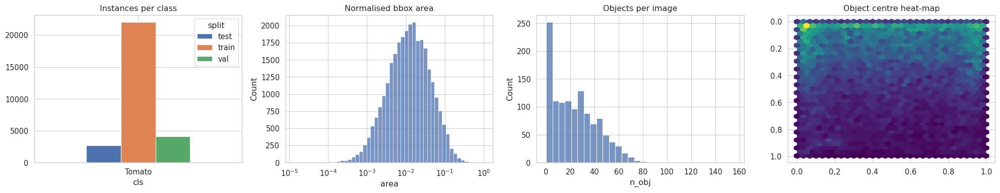

In [5]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
def read_labels(lbl_file):
    rows = []
    for line in open(lbl_file).read().strip().splitlines():
        p = line.split()
        if len(p) < 5: continue
        c = int(float(p[0])); v = list(map(float, p[1:]))
        if len(v) == 4: xc, yc, w, h = v
        else:   # polygon -> bounding box
            xs, ys = v[0::2], v[1::2]; xc, yc = (min(xs)+max(xs))/2, (min(ys)+max(ys))/2; w, h = max(xs)-min(xs), max(ys)-min(ys)
        rows.append((c, xc, yc, w, h))
    return rows

recs, img_info = [], []
for split, d in SPLIT_DIR.items():
    if split == "test" and SPLITS.get("test") is None: continue
    imgs = [p for p in (d/"images").iterdir() if p.suffix.lower() in IMG_EXT]
    for p in imgs:
        lf = d/"labels"/(p.stem + ".txt")
        rows = read_labels(lf) if lf.exists() else []
        img_info.append(dict(split=split, file=p.name, n_obj=len(rows)))
        for r in rows: recs.append(dict(split=split, file=p.name, cls=CLASS_NAMES[r[0]] if r[0] < NC else str(r[0]), xc=r[1], yc=r[2], w=r[3], h=r[4]))
df_obj, df_img = pd.DataFrame(recs), pd.DataFrame(img_info)
df_obj["area"] = df_obj.w * df_obj.h

summary = df_img.groupby("split").agg(images=("file","count"), instances=("n_obj","sum"), mean_obj_per_img=("n_obj","mean"), empty_imgs=("n_obj", lambda s: (s==0).sum()))
cls_tab = df_obj.pivot_table(index="cls", columns="split", values="file", aggfunc="count", fill_value=0)
print(summary, "\n\n", cls_tab)
summary.to_csv(RES/"dataset_summary.csv"); cls_tab.to_csv(RES/"dataset_class_distribution.csv")

# image resolution (sample)
sizes = []
for p in list((SPLIT_DIR["train"]/"images").iterdir())[:200]:
    im = cv2.imread(str(p));
    if im is not None: sizes.append(im.shape[:2][::-1])
print("Sample image sizes (W,H) – most common:", pd.Series(sizes).value_counts().head(3).to_dict())

# object size categories (COCO-like, on normalised area at 640x640 equivalent)
a640 = df_obj.area * 640 * 640
df_obj["size_cat"] = pd.cut(a640, [0, 32**2, 96**2, 1e9], labels=["small","medium","large"])
size_tab = df_obj.groupby(["split","size_cat"]).size().unstack(fill_value=0); print(size_tab); size_tab.to_csv(RES/"dataset_object_sizes.csv")

fig, ax = plt.subplots(1, 4, figsize=(20, 4))
cls_tab.plot(kind="bar", ax=ax[0], rot=0); ax[0].set_title("Instances per class")
sns.histplot(df_obj.area, bins=50, log_scale=(True, False), ax=ax[1]); ax[1].set_title("Normalised bbox area")
sns.histplot(df_img.n_obj, bins=30, ax=ax[2]); ax[2].set_title("Objects per image")
ax[3].hexbin(df_obj.xc, df_obj.yc, gridsize=30, cmap="viridis"); ax[3].set_title("Object centre heat-map"); ax[3].invert_yaxis()
plt.tight_layout(); plt.savefig(FIGS/"dataset_analysis.png", dpi=300); plt.show()

## 5. Write `data.yaml` and visualise ground-truth samples

names:
  0: Cabbage
  1: Tomato
  2: Sesame
nc: 3
path: /kaggle/working/weed_exp/data
test: test/images
train: train/images
val: valid/images



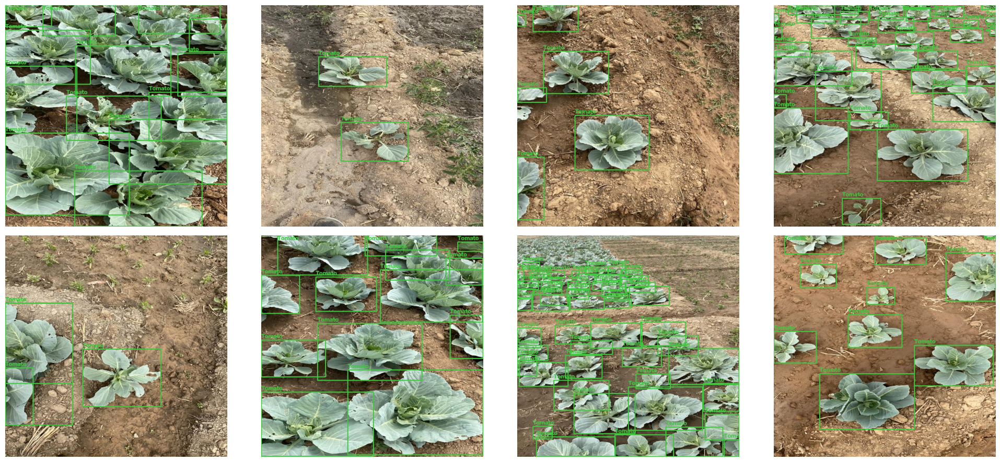

In [6]:
YAML = WORK/"agriaiseg.yaml"
yaml.safe_dump(dict(path=str(DATA.resolve()),
                    train=f"{SPLITS['train']}/images", val=f"{SPLITS['val']}/images",
                    test=f"{SPLIT_DIR['test'].name}/images",
                    nc=NC, names={i: n for i, n in enumerate(CLASS_NAMES)}), open(YAML, "w"))
print(open(YAML).read())

palette = [(255,64,64), (64,200,64), (64,128,255), (255,200,0), (200,0,200)]
def draw_gt(img_path, lbl_path):
    im = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB); H, W = im.shape[:2]
    for c, xc, yc, w, h in read_labels(lbl_path):
        x1, y1, x2, y2 = int((xc-w/2)*W), int((yc-h/2)*H), int((xc+w/2)*W), int((yc+h/2)*H)
        cv2.rectangle(im, (x1,y1), (x2,y2), palette[c % 5], max(2, W//300))
        cv2.putText(im, CLASS_NAMES[c], (x1, max(15,y1-5)), cv2.FONT_HERSHEY_SIMPLEX, max(0.6, W/1500), palette[c % 5], 2)
    return im
tr_imgs = sorted((SPLIT_DIR["train"]/"images").iterdir()); random.Random(1).shuffle(tr_imgs)
fig, axs = plt.subplots(2, 4, figsize=(20, 9))
for a, p in zip(axs.ravel(), tr_imgs[:8]):
    a.imshow(draw_gt(p, SPLIT_DIR["train"]/"labels"/(p.stem+".txt"))); a.axis("off")
plt.tight_layout(); plt.savefig(FIGS/"dataset_samples.png", dpi=200); plt.show()

## 6. Train all models (identical settings). Resumable: finished runs are skipped.

In [8]:
from ultralytics import YOLO
TIMES_F = RES/"train_times.json"
train_times = json.load(open(TIMES_F)) if TIMES_F.exists() else {}
FAILED = {}

for seed in SEEDS:
    for name, weights in MODELS.items():
        run = f"{name}_s{seed}"
        best = RUNS/run/"weights"/"best.pt"
        if best.exists():
            print(f"[skip] {run} already trained"); continue
        print(f"\n===== Training {run} =====")
        try:
            set_seed(seed)
            model = YOLO(weights)
            t0 = time.time()
            model.train(data=str(YAML), project=str(RUNS), name=run, exist_ok=True, seed=seed,
                        device=DEVICE, plots=True, verbose=False, **TRAIN_KW)
            train_times[run] = (time.time() - t0) / 60
            json.dump(train_times, open(TIMES_F, "w"), indent=2)
        except Exception as e:
            FAILED[run] = repr(e); print("FAILED:", run, e)
        finally:
            del model; gc.collect(); torch.cuda.empty_cache()
print("\nFailed runs:", FAILED or "none")


===== Training YOLO11n_s0 =====
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=weed_exp/agriaiseg.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=YOLO11n_s0, nbs=64, nms=None, op

## 7. Evaluate on the TEST split (same conf/IoU thresholds for all)

In [ ]:
rows, per_class_rows = [], []
for seed in SEEDS:
    for name in MODELS:
        run = f"{name}_s{seed}"; best = RUNS/run/"weights"/"best.pt"
        if not best.exists(): continue
        m = YOLO(str(best))
        r = m.val(data=str(YAML), split="test", device=DEVICE, project=str(EVAL), name=run, exist_ok=True,
                  plots=True, verbose=False, **EVAL_KW)
        P, R = float(r.box.mp), float(r.box.mr)
        info = m.info(detailed=False, verbose=False, imgsz=TRAIN_KW["imgsz"])
        rows.append(dict(model=name, seed=seed, precision=P, recall=R, f1=2*P*R/(P+R+1e-9),
                         mAP50=float(r.box.map50), mAP75=float(r.box.map75), mAP50_95=float(r.box.map),
                         params_M=sum(p.numel() for p in m.model.parameters())/1e6,
                         gflops=float(info[3]), size_MB=os.path.getsize(best)/1e6,
                         train_min=train_times.get(run, np.nan)))
        for ci, ap, ap50 in zip(r.box.ap_class_index, r.box.ap, r.box.ap50):
            per_class_rows.append(dict(model=name, seed=seed, cls=CLASS_NAMES[int(ci)], AP50=float(ap50), AP50_95=float(ap)))
        del m; gc.collect(); torch.cuda.empty_cache()
df_acc, df_cls = pd.DataFrame(rows), pd.DataFrame(per_class_rows)
df_acc.to_csv(RES/"accuracy_per_run.csv", index=False); df_cls.to_csv(RES/"per_class_per_run.csv", index=False)
df_acc.round(4)

In [8]:
from pathlib import Path
import re
import os
import gc
import torch
import pandas as pd
import numpy as np
from ultralytics import YOLO

rows, per_class_rows = [], []

for name in MODELS:
  # Extract version number (e.g., '11' from 'YOLO11n')
  match = re.search(r"\d+", name)
  if not match:
    continue
  version = match.group()

  # Construct path with lowercase folder name and matching weight file name
  best = Path(
      f"/kaggle/input/models/pushpendrakumarkiet/yolo{version}/pytorch/default/1/best{version}.pt"
  )

  if not best.exists():
    print(f"Skipping: {best} not found.")
    continue

  m = YOLO(str(best))
  run = name
  r = m.val(
      data=str(YAML),
      split="test",
      device=DEVICE,
      project=str(EVAL),
      name=run,
      exist_ok=True,
      plots=True,
      verbose=False,
      **EVAL_KW,
  )

  P, R = float(r.box.mp), float(r.box.mr)

  # Safely handle model info and GFLOPs extraction
  try:
    info = m.info(detailed=False, verbose=False, imgsz=TRAIN_KW["imgsz"])
    gflops = float(info[3]) if info is not None and len(info) > 3 else 0.0
  except Exception:
    gflops = float(getattr(m, "gflops", 0.0))

  # Safely lookup train time if train_times variable exists
  train_min = (
      train_times.get(run, np.nan) if "train_times" in globals() else np.nan
  )

  rows.append(
      dict(
          model=name,
          precision=P,
          recall=R,
          f1=2 * P * R / (P + R + 1e-9),
          mAP50=float(r.box.map50),
          mAP75=float(r.box.map75),
          mAP50_95=float(r.box.map),
          params_M=sum(p.numel() for p in m.model.parameters()) / 1e6,
          gflops=gflops,
          size_MB=os.path.getsize(best) / 1e6,
          train_min=train_min,
      )
  )

  for ci, ap, ap50 in zip(r.box.ap_class_index, r.box.ap, r.box.ap50):
    per_class_rows.append(
        dict(
            model=name,
            cls=CLASS_NAMES[int(ci)],
            AP50=float(ap50),
            AP50_95=float(ap),
        )
    )

  del m
  gc.collect()
  torch.cuda.empty_cache()

df_acc, df_cls = pd.DataFrame(rows), pd.DataFrame(per_class_rows)
df_acc.to_csv(RES / "accuracy_per_run.csv", index=False)
df_cls.to_csv(RES / "per_class_per_run.csv", index=False)
df_acc.round(4)

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLOv5n summary (fused): 85 layers, 2,630,489 parameters, 0 gradients, 7.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2341.9±774.4 MB/s, size: 126.0 KB)
val: Scanning /kaggle/working/weed_exp/data/test/labels.cache... 119 images, 0 backgrounds, 3 corrupt: 100% ━━━━━━━━━━━━ 119/119 19.2Mit/s 0.0s
val: /kaggle/working/weed_exp/data/test/images/1215_JPG.rf.304e8bd3a7b247377575ba9c613897b0.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: /kaggle/working/weed_exp/data/test/images/208_JPG.rf.c5a4ac0ba970b78e0c95b5c256d9efcc.jpg: 1 duplicate labels removed
val: /kaggle/working/weed_exp/data/test/images/214_JPG.rf.45e53c4e927f1619e753580d16f698e9.jpg: 1 duplicate labels removed
val: /kaggle/working/weed_exp/data/test/images/680_JPG.rf.a6a64241e08506b3fe9a61ed84a43616.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: /kaggle/working/weed_exp/

,model,precision,recall,f1,mAP50,mAP75,mAP50_95,params_M,gflops,size_MB,train_min
0,YOLOv5n,0.9178,0.8990,0.9083,0.9440,0.8793,0.8251,2.6361,0.0,5.5355,NaN
1,YOLOv8n,0.9119,0.9136,0.9127,0.9486,0.8828,0.8310,3.1385,0.0,6.5147,NaN
2,YOLOv9t,0.9258,0.9020,0.9137,0.9525,0.8929,0.8387,2.1100,0.0,4.8625,NaN
3,YOLOv10n,0.9281,0.8874,0.9073,0.9466,0.8832,0.8295,2.7381,0.0,5.8284,NaN
4,YOLO11n,0.9324,0.8851,0.9082,0.9458,0.8788,0.8295,2.6054,0.0,5.5130,NaN
5,YOLO12n,0.9086,0.8997,0.9041,0.9503,0.8840,0.8317,2.5836,0.0,5.5610,NaN
6,YOLO26n,0.9228,0.8944,0.9084,0.9496,0.8881,0.8266,2.5349,0.0,5.4607,NaN


## 8. Latency / FPS benchmark (batch = 1, end-to-end: pre-process + inference + NMS)
CPU latency is the proxy for edge deployment (Raspberry Pi / Jetson-class devices behave proportionally).

In [12]:
from pathlib import Path
import re
import os
import gc
import time
import torch
import cv2
import numpy as np
import pandas as pd
from ultralytics import YOLO

test_imgs = sorted(
    [
        p
        for p in (SPLIT_DIR["test"] / "images").iterdir()
        if p.suffix.lower() in IMG_EXT
    ]
)[:LAT_N]
bench_imgs = [cv2.imread(str(p)) for p in test_imgs]


def bench(weights, device):
  m = YOLO(str(weights))
  ts = []
  if device == "cpu":
    torch.set_num_threads(CPU_THREADS)
  for i in range(LAT_WARMUP):
    m.predict(
        bench_imgs[i % len(bench_imgs)],
        imgsz=TRAIN_KW["imgsz"],
        device=device,
        verbose=False,
    )
  for im in bench_imgs:
    if device != "cpu":
      torch.cuda.synchronize()
    t = time.perf_counter()
    m.predict(
        im, imgsz=TRAIN_KW["imgsz"], device=device, verbose=False, conf=0.25
    )
    if device != "cpu":
      torch.cuda.synchronize()
    ts.append((time.perf_counter() - t) * 1000)
  ts = np.array(ts)
  del m
  gc.collect()
  return ts.mean(), ts.std(), 1000 / ts.mean()


lat_rows = []
for name in MODELS:
  # Extract version number (e.g., '11' from 'YOLO11n')
  match = re.search(r"\d+", name)
  if not match:
    continue
  version = match.group()

  # Construct the updated path using the lowercase folder structure[cite: 1, 2]
  best = Path(
      f"/kaggle/input/models/pushpendrakumarkiet/yolo{version}/pytorch/default/1/best{version}.pt"
  )

  if not best.exists():
    print(f"Skipping: {best} not found.")
    continue

  run = name
  row = dict(model=name)
  row["cpu_ms"], row["cpu_ms_std"], row["cpu_fps"] = bench(best, "cpu")
  if torch.cuda.is_available():
    row["gpu_ms"], row["gpu_ms_std"], row["gpu_fps"] = bench(best, 0)
  lat_rows.append(row)
  print(
      run,
      {k: round(v, 2) for k, v in row.items() if isinstance(v, (float, int))},
  )

df_lat = pd.DataFrame(lat_rows)
df_lat.to_csv(RES / "latency_per_run.csv", index=False)

YOLOv5n {'cpu_ms': np.float64(75.58), 'cpu_ms_std': np.float64(2.93), 'cpu_fps': np.float64(13.23), 'gpu_ms': np.float64(8.07), 'gpu_ms_std': np.float64(0.35), 'gpu_fps': np.float64(123.97)}
YOLOv8n {'cpu_ms': np.float64(78.93), 'cpu_ms_std': np.float64(5.3), 'cpu_fps': np.float64(12.67), 'gpu_ms': np.float64(7.36), 'gpu_ms_std': np.float64(0.29), 'gpu_fps': np.float64(135.88)}
YOLOv9t {'cpu_ms': np.float64(112.24), 'cpu_ms_std': np.float64(5.08), 'cpu_fps': np.float64(8.91), 'gpu_ms': np.float64(17.21), 'gpu_ms_std': np.float64(0.72), 'gpu_fps': np.float64(58.1)}
YOLOv10n {'cpu_ms': np.float64(77.29), 'cpu_ms_std': np.float64(4.66), 'cpu_fps': np.float64(12.94), 'gpu_ms': np.float64(8.64), 'gpu_ms_std': np.float64(0.45), 'gpu_fps': np.float64(115.8)}
YOLO11n {'cpu_ms': np.float64(74.93), 'cpu_ms_std': np.float64(4.52), 'cpu_fps': np.float64(13.35), 'gpu_ms': np.float64(9.46), 'gpu_ms_std': np.float64(0.35), 'gpu_fps': np.float64(105.72)}
YOLO12n {'cpu_ms': np.float64(97.15), 'cpu_ms_s

## 9. Master results table (mean ± std over seeds) + LaTeX

In [14]:
# Merge dataframes on 'model' instead of ['model', 'seed']
df_all = df_acc.merge(df_lat, on=["model"])
num_cols = [c for c in df_all.columns if c != "model"]

# Group by model
g = df_all.groupby("model", sort=False)[num_cols]
MEAN, STD = g.mean(), g.std().fillna(0)
MEAN.to_csv(RES / "master_mean.csv")
STD.to_csv(RES / "master_std.csv")


# Simplified formatting since there are no multiple seeds (len(SEEDS) == 1 logic)
def fmt(col, nd=3):
  return MEAN[col].map(lambda v: f"{v:.{nd}f}")


tbl = pd.DataFrame({
    "Params (M)": MEAN.params_M.map("{:.2f}".format),
    "GFLOPs": MEAN.gflops.map("{:.1f}".format),
    "Size (MB)": MEAN.size_MB.map("{:.1f}".format),
    "P": fmt("precision"),
    "R": fmt("recall"),
    "F1": fmt("f1"),
    "mAP@0.5": fmt("mAP50"),
    "mAP@0.5:0.95": fmt("mAP50_95"),
    "CPU ms": fmt("cpu_ms", 1),
    "CPU FPS": fmt("cpu_fps", 1),
})

if "gpu_ms" in MEAN.columns:
  tbl["GPU ms"] = fmt("gpu_ms", 1)
  tbl["GPU FPS"] = fmt("gpu_fps", 0)

if "train_min" in MEAN.columns:
  tbl["Train (min)"] = MEAN.train_min.map("{:.0f}".format)

tbl.to_csv(RES / "table_main_results.csv")
open(RES / "table_main_results.tex", "w").write(
    tbl.to_latex(
        caption="Comparison of lightweight detectors on the test set.",
        label="tab:main",
        escape=False,
    )
)
tbl

,Params (M),GFLOPs,Size (MB),P,R,F1,mAP@0.5,mAP@0.5:0.95,CPU ms,CPU FPS,GPU ms,GPU FPS,Train (min)
model,,,,,,,,,,,,,
YOLOv5n,2.64,0.0,5.5,0.918,0.899,0.908,0.944,0.825,75.6,13.2,8.1,124,nan
YOLOv8n,3.14,0.0,6.5,0.912,0.914,0.913,0.949,0.831,78.9,12.7,7.4,136,nan
YOLOv9t,2.11,0.0,4.9,0.926,0.902,0.914,0.953,0.839,112.2,8.9,17.2,58,nan
YOLOv10n,2.74,0.0,5.8,0.928,0.887,0.907,0.947,0.829,77.3,12.9,8.6,116,nan
YOLO11n,2.61,0.0,5.5,0.932,0.885,0.908,0.946,0.830,74.9,13.3,9.5,106,nan
YOLO12n,2.58,0.0,5.6,0.909,0.900,0.904,0.950,0.832,97.2,10.3,13.5,74,nan
YOLO26n,2.53,0.0,5.5,0.923,0.894,0.908,0.950,0.827,74.0,13.5,11.2,89,nan


## 10. Comparison plots (accuracy, efficiency, Pareto front)

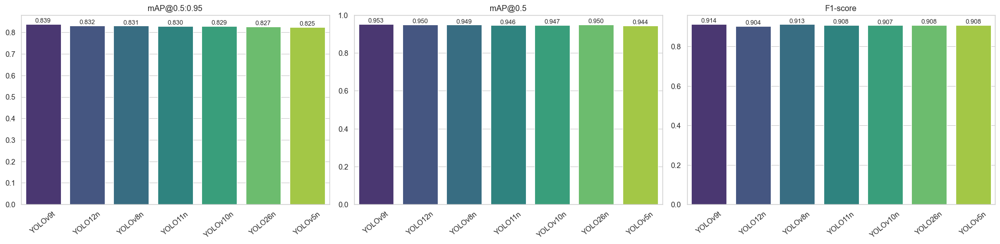

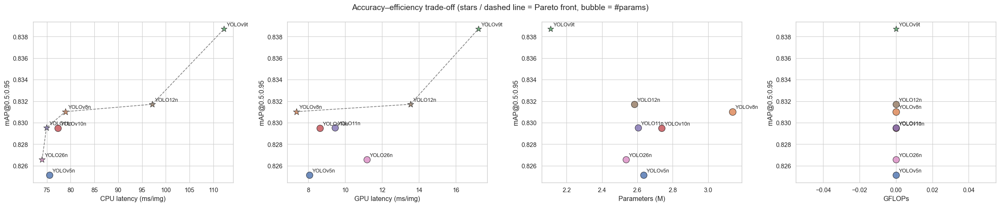

Pareto-optimal (CPU latency vs mAP50-95): ['YOLOv8n', 'YOLOv9t', 'YOLO11n', 'YOLO12n', 'YOLO26n']


In [15]:
order = MEAN.sort_values("mAP50_95", ascending=False).index
fig, ax = plt.subplots(1, 3, figsize=(20, 5))
for a, (col, t) in zip(ax, [("mAP50_95", "mAP@0.5:0.95"), ("mAP50", "mAP@0.5"), ("f1", "F1-score")]):
    sns.barplot(x=MEAN.loc[order, col].index, y=MEAN.loc[order, col].values, ax=a, palette="viridis")
    for i, v in enumerate(MEAN.loc[order, col].values): a.text(i, v, f"{v:.3f}", ha="center", va="bottom", fontsize=9)
    a.set_title(t); a.set_xlabel(""); a.tick_params(axis="x", rotation=40)
plt.tight_layout(); plt.savefig(FIGS/"accuracy_bars.png", dpi=300); plt.show()

def pareto(df, xcol, ycol):   # minimise x, maximise y
    front = []
    for i, r in df.iterrows():
        if not ((df[xcol] <= r[xcol]) & (df[ycol] >= r[ycol]) & ((df[xcol] < r[xcol]) | (df[ycol] > r[ycol]))).any(): front.append(i)
    return front

xs = [("cpu_ms", "CPU latency (ms/img)"), ("params_M", "Parameters (M)"), ("gflops", "GFLOPs")]
if "gpu_ms" in MEAN: xs.insert(1, ("gpu_ms", "GPU latency (ms/img)"))
fig, ax = plt.subplots(1, len(xs), figsize=(6*len(xs), 5))
for a, (xc, xl) in zip(ax, xs):
    pf = pareto(MEAN, xc, "mAP50_95")
    for n, r in MEAN.iterrows():
        a.scatter(r[xc], r.mAP50_95, s=60 + 25*r.params_M, alpha=.8, edgecolor="k", marker="*" if n in pf else "o")
        a.annotate(n, (r[xc], r.mAP50_95), textcoords="offset points", xytext=(5, 5), fontsize=9)
    pts = MEAN.loc[pf].sort_values(xc); a.plot(pts[xc], pts.mAP50_95, "--", color="gray")
    a.set_xlabel(xl); a.set_ylabel("mAP@0.5:0.95")
plt.suptitle("Accuracy–efficiency trade-off (stars / dashed line = Pareto front, bubble = #params)"); plt.tight_layout()
plt.savefig(FIGS/"pareto.png", dpi=300); plt.show()
print("Pareto-optimal (CPU latency vs mAP50-95):", list(MEAN.loc[pareto(MEAN, "cpu_ms", "mAP50_95")].index))

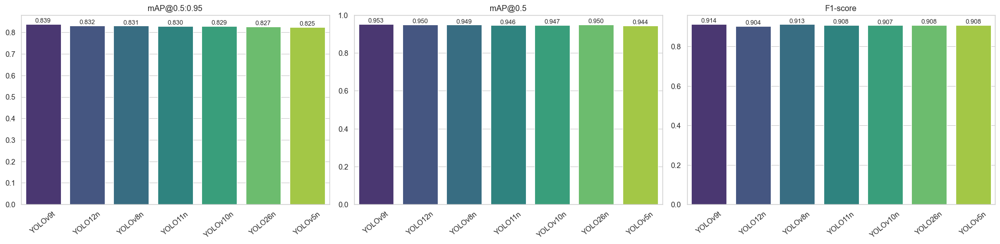

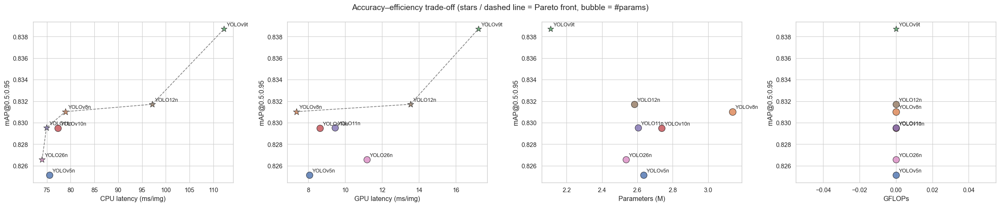

Pareto-optimal (CPU latency vs mAP50-95): ['YOLOv8n', 'YOLOv9t', 'YOLO11n', 'YOLO12n', 'YOLO26n']


In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# 1. Accuracy Bar Plots
order = MEAN.sort_values("mAP50_95", ascending=False).index
fig, ax = plt.subplots(1, 3, figsize=(20, 5))
for a, (col, t) in zip(
    ax,
    [
        ("mAP50_95", "mAP@0.5:0.95"),
        ("mAP50", "mAP@0.5"),
        ("f1", "F1-score"),
    ],
):
  sns.barplot(
      x=MEAN.loc[order, col].index,
      y=MEAN.loc[order, col].values,
      ax=a,
      palette="viridis",
      hue=MEAN.loc[order, col].index,
      legend=False,
  )
  for i, v in enumerate(MEAN.loc[order, col].values):
    a.text(i, v, f"{v:.3f}", ha="center", va="bottom", fontsize=9)
  a.set_title(t)
  a.set_xlabel("")
  a.tick_params(axis="x", rotation=40)
plt.tight_layout()
plt.savefig(FIGS / "accuracy_bars.png", dpi=300)
plt.show()


# 2. Pareto Front Calculation & Plots
def pareto(df, xcol, ycol):  # minimise x, maximise y
  front = []
  for i, r in df.iterrows():
    if not (
        (df[xcol] <= r[xcol])
        & (df[ycol] >= r[ycol])
        & ((df[xcol] < r[xcol]) | (df[ycol] > r[ycol]))
    ).any():
      front.append(i)
  return front


xs = [
    ("cpu_ms", "CPU latency (ms/img)"),
    ("params_M", "Parameters (M)"),
    ("gflops", "GFLOPs"),
]
if "gpu_ms" in MEAN.columns:
  xs.insert(1, ("gpu_ms", "GPU latency (ms/img)"))

fig, ax = plt.subplots(1, len(xs), figsize=(6 * len(xs), 5))
# Ensure ax is always iterable even if len(xs) == 1
if len(xs) == 1:
  ax = [ax]

for a, (xc, xl) in zip(ax, xs):
  pf = pareto(MEAN, xc, "mAP50_95")
  for n, r in MEAN.iterrows():
    a.scatter(
        r[xc],
        r.mAP50_95,
        s=60 + 25 * r.params_M,
        alpha=0.8,
        edgecolor="k",
        marker="*" if n in pf else "o",
    )
    a.annotate(
        n, (r[xc], r.mAP50_95), textcoords="offset points", xytext=(5, 5), fontsize=9
    )
  pts = MEAN.loc[pf].sort_values(xc)
  a.plot(pts[xc], pts.mAP50_95, "--", color="gray")
  a.set_xlabel(xl)
  a.set_ylabel("mAP@0.5:0.95")

plt.suptitle(
    "Accuracy–efficiency trade-off (stars / dashed line = Pareto front, bubble ="
    " #params)"
)
plt.tight_layout()
plt.savefig(FIGS / "pareto.png", dpi=300)
plt.show()

print(
    "Pareto-optimal (CPU latency vs mAP50-95):",
    list(MEAN.loc[pareto(MEAN, "cpu_ms", "mAP50_95")].index),
)

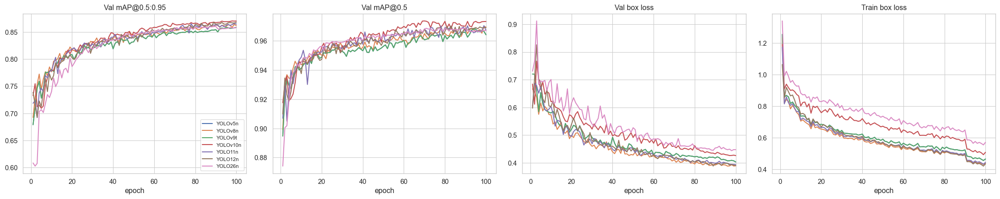

In [19]:
import matplotlib.pyplot as plt
import pandas as pd
import re

curves = {}
for name in MODELS:
  # Extract the version number (e.g., '11' from 'YOLO11n' or 'yolo11')
  match = re.search(r"\d+", name)
  if not match:
    continue
  version = match.group()

  # Path to the respective results CSV file based on your image
  f = Path(
      f"/kaggle/input/datasets/pushpendrakumarkiet/runcsvs/results{version}.csv"
  )

  if f.exists():
    d = pd.read_csv(f)
    d.columns = [c.strip() for c in d.columns]
    curves[name] = d
  else:
    print(f"Warning: {f} not found.")

keys = [
    ("metrics/mAP50-95(B)", "Val mAP@0.5:0.95"),
    ("metrics/mAP50(B)", "Val mAP@0.5"),
    ("val/box_loss", "Val box loss"),
    ("train/box_loss", "Train box loss"),
]

fig, ax = plt.subplots(1, 4, figsize=(22, 4.5))
has_curves = False

for a, (k, t) in zip(ax, keys):
  for n, d in curves.items():
    if k in d.columns:
      a.plot(d["epoch"], d[k], label=n, lw=1.5)
      has_curves = True
  a.set_title(t)
  a.set_xlabel("epoch")

if has_curves:
  ax[0].legend(fontsize=8)
  plt.tight_layout()
  plt.savefig(FIGS / "training_curves.png", dpi=300)
  plt.show()
else:
  plt.close(fig)
  print("No matching curve columns found in the CSV files.")

## 11. Training curves (seed 0)

## 12. Per-class results

cls,Tomato,mean
model,,
YOLOv5n,0.825,0.825
YOLOv8n,0.831,0.831
YOLOv9t,0.839,0.839
YOLOv10n,0.829,0.829
YOLO11n,0.830,0.830
YOLO12n,0.832,0.832
YOLO26n,0.827,0.827


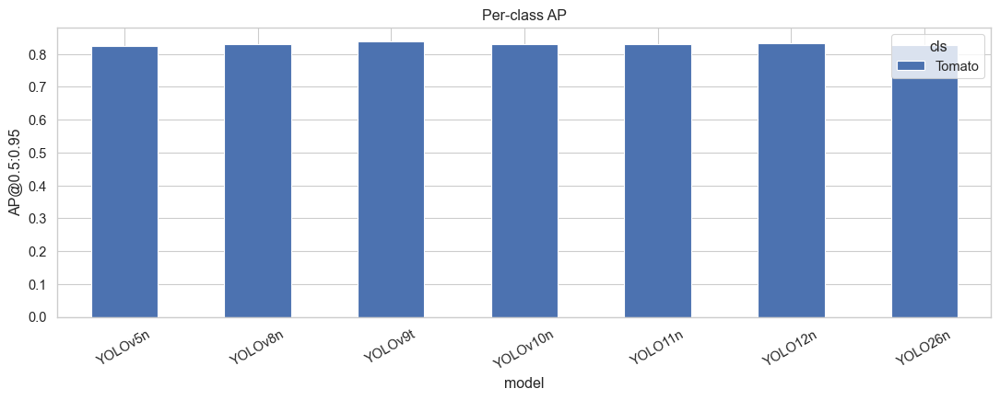

No normalized confusion matrix images found in the evaluation directories.


In [22]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Per-class metrics summary (without seed grouping)
pc = (
    df_cls.groupby(["model", "cls"], sort=False)[["AP50", "AP50_95"]]
    .mean()
    .reset_index()
)
pc_tab = (
    pc.pivot(index="model", columns="cls", values="AP50_95")
    .loc[MEAN.index]
    .copy()
)
pc_tab["mean"] = pc_tab.mean(axis=1)

pc_tab.round(3).to_csv(RES / "table_per_class_AP50_95.csv")
display(pc_tab.round(3))

(
    pc.pivot(index="model", columns="cls", values="AP50")
    .loc[MEAN.index]
    .round(3)
    .to_csv(RES / "table_per_class_AP50.csv")
)

# Per-class AP bar plot
ax = pc_tab.drop(columns="mean").plot(kind="bar", figsize=(11, 4.5), rot=30)
ax.set_ylabel("AP@0.5:0.95")
ax.set_title("Per-class AP")
plt.tight_layout()
plt.savefig(FIGS / "per_class_ap.png", dpi=300)
plt.show()

# Confusion matrices of every model side by side (updated path without seed)
cms = [(n, EVAL / n / "confusion_matrix_normalized.png") for n in MODELS]
cms = [(n, p) for n, p in cms if p.exists()]

cols = 4
rws = int(np.ceil(len(cms) / cols)) if cms else 1
fig, axs = plt.subplots(
    rws, cols, figsize=(5 * cols, 4.5 * max(rws, 1))
)  # ensure safe sizing
axs = np.array(axs).ravel()

for a in axs:
  a.axis("off")

if cms:
  for a, (n, p) in zip(axs, cms):
    a.imshow(plt.imread(p))
    a.set_title(n)
  plt.tight_layout()
  plt.savefig(FIGS / "confusion_matrices_all.png", dpi=200)
  plt.show()
else:
  plt.close(fig)
  print(
      "No normalized confusion matrix images found in the evaluation directories."
  )

## 13. Composite ranking and best-model recommendation
Min-max normalised weighted score (weights in `RANK_W`). Accuracy-only, speed-only and balanced rankings are all reported so reviewers can see the recommendation is not an artefact of the weights.

,acc,speed,params,flops,Composite,AccuracyFirst,EdgeFirst,Equal,mAP50_95,CPU_FPS,Params_M,Rank
model,,,,,,,,,,,,
YOLOv9t,1.000,0.000,1.000,1.0,0.750,0.900,0.600,0.750,0.839,8.909,2.110,1
YOLO11n,0.325,0.964,0.518,1.0,0.593,0.432,0.711,0.702,0.830,13.346,2.605,2
YOLOv10n,0.321,0.876,0.389,1.0,0.553,0.414,0.655,0.647,0.829,12.938,2.738,3
YOLOv8n,0.435,0.817,0.000,1.0,0.547,0.479,0.607,0.563,0.831,12.670,3.138,4
YOLO12n,0.485,0.301,0.540,1.0,0.510,0.495,0.497,0.581,0.832,10.293,2.584,5
YOLO26n,0.106,1.000,0.587,1.0,0.501,0.264,0.670,0.673,0.827,13.510,2.535,6
YOLOv5n,0.000,0.939,0.488,1.0,0.421,0.168,0.599,0.607,0.825,13.231,2.636,7



>>> BEST OVERALL (composite): YOLOv9t
>>> Highest accuracy: YOLOv9t | Fastest (CPU): YOLO26n | Smallest: YOLOv9t
>>> Winner under each weighting: {'Composite': 'YOLOv9t', 'AccuracyFirst': 'YOLOv9t', 'EdgeFirst': 'YOLO11n', 'Equal': 'YOLOv9t'}


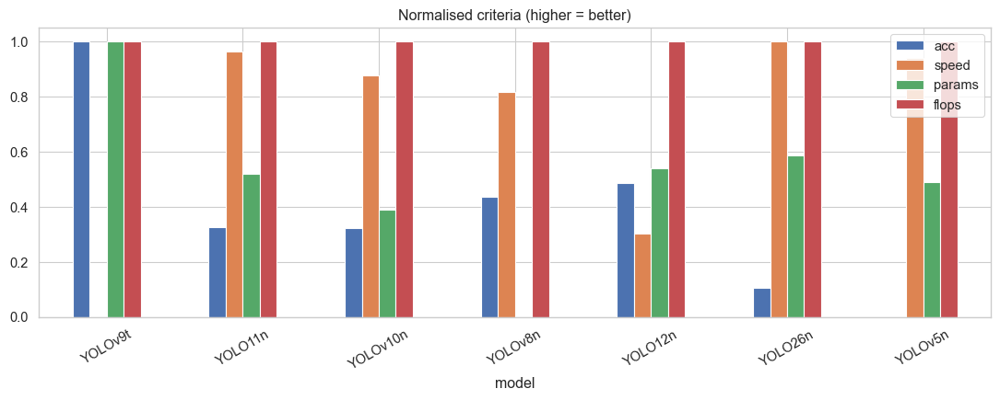

In [23]:
def mm(s, higher_better=True):
    s = (s - s.min()) / (s.max() - s.min() + 1e-12); return s if higher_better else 1 - s
S = pd.DataFrame(index=MEAN.index)
S["acc"] = mm(MEAN.mAP50_95); S["speed"] = mm(MEAN.cpu_fps); S["params"] = mm(MEAN.params_M, False); S["flops"] = mm(MEAN.gflops, False)
S["Composite"] = (RANK_W["mAP50_95"]*S.acc + RANK_W["cpu_fps"]*S.speed + RANK_W["params_M"]*S.params + RANK_W["gflops"]*S.flops)
# sensitivity: alternative weightings
for tag, w in {"AccuracyFirst": (.8, .1, .05, .05), "EdgeFirst": (.3, .4, .15, .15), "Equal": (.25, .25, .25, .25)}.items():
    S[tag] = w[0]*S.acc + w[1]*S.speed + w[2]*S.params + w[3]*S.flops
S["mAP50_95"] = MEAN.mAP50_95; S["CPU_FPS"] = MEAN.cpu_fps; S["Params_M"] = MEAN.params_M
S = S.sort_values("Composite", ascending=False); S["Rank"] = range(1, len(S)+1)
S.round(3).to_csv(RES/"table_ranking.csv"); display(S.round(3))
print(f"\n>>> BEST OVERALL (composite): {S.index[0]}")
print(">>> Highest accuracy:", MEAN.mAP50_95.idxmax(), "| Fastest (CPU):", MEAN.cpu_fps.idxmax(), "| Smallest:", MEAN.params_M.idxmin())
print(">>> Winner under each weighting:", {c: S[c].idxmax() for c in ["Composite", "AccuracyFirst", "EdgeFirst", "Equal"]})
ax = S[["acc", "speed", "params", "flops"]].plot(kind="bar", stacked=False, figsize=(11, 4.5), rot=30); ax.set_title("Normalised criteria (higher = better)")
plt.tight_layout(); plt.savefig(FIGS/"ranking_criteria.png", dpi=300); plt.show()

## 14. Qualitative predictions on the same test images

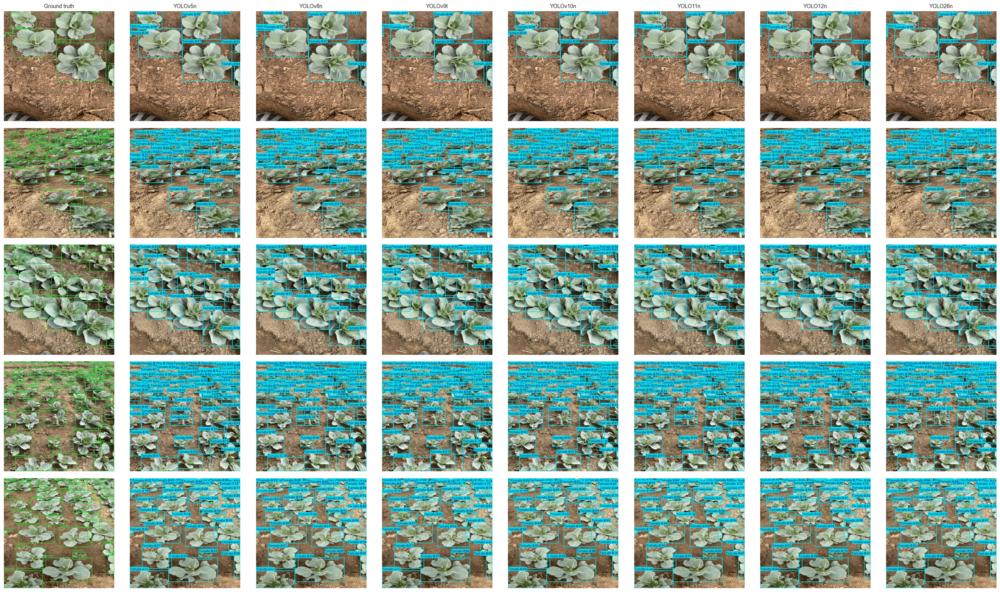

58799

In [25]:
import random
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import gc
import re
from ultralytics import YOLO

# 1. Pick 5 random test images
pick = random.Random(7).sample(
    sorted((SPLIT_DIR["test"] / "images").iterdir()), 5
)

# 2. Check and load available models using the new path structure
names_ok = []
model_paths = {}

for n in MODELS:
  match = re.search(r"\d+", n)
  if not match:
    continue
  version = match.group()
  best = Path(
      f"/kaggle/input/models/pushpendrakumarkiet/yolo{version}/pytorch/default/1/best{version}.pt"
  )
  if best.exists():
    names_ok.append(n)
    model_paths[n] = best

loaded = {n: YOLO(str(model_paths[n])) for n in names_ok}

# 3. Plot grid of ground truths vs predictions
fig, axs = plt.subplots(
    len(pick),
    len(names_ok) + 1,
    figsize=(3.3 * (len(names_ok) + 1), 3.1 * len(pick)),
)

# Ensure axs is 2D even if len(pick) == 1 or len(names_ok) == 0
if len(pick) == 1:
  axs = axs[None, :]

for i, p in enumerate(pick):
  axs[i, 0].imshow(
      draw_gt(p, SPLIT_DIR["test"] / "labels" / (p.stem + ".txt"))
  )
  axs[i, 0].axis("off")
  if i == 0:
    axs[i, 0].set_title("Ground truth", fontsize=10)

  for j, n in enumerate(names_ok, 1):
    res = loaded[n].predict(
        str(p),
        imgsz=TRAIN_KW["imgsz"],
        conf=0.25,
        device=DEVICE,
        verbose=False,
    )[0]
    axs[i, j].imshow(
        cv2.cvtColor(res.plot(line_width=2), cv2.COLOR_BGR2RGB)
    )
    axs[i, j].axis("off")
    if i == 0:
      axs[i, j].set_title(n, fontsize=10)

plt.tight_layout()
plt.savefig(FIGS / "qualitative_predictions.png", dpi=250)
plt.show()

del loaded
gc.collect()

## 15. Robustness study: illumination, blur, noise (simulated field conditions on the test set)

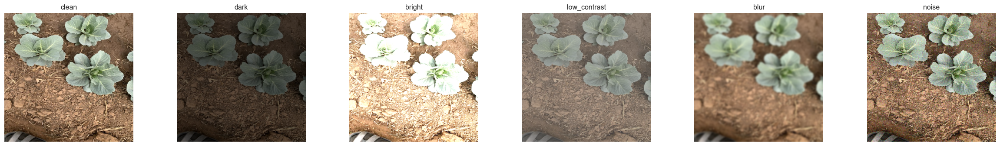

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLOv5n summary (fused): 85 layers, 2,630,489 parameters, 0 gradients, 7.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2539.3±563.2 MB/s, size: 122.4 KB)
val: Scanning /kaggle/working/weed_exp/data/test/labels.cache... 119 images, 0 backgrounds, 3 corrupt: 100% ━━━━━━━━━━━━ 119/119 35.7Mit/s 0.0s
val: /kaggle/working/weed_exp/data/test/images/1215_JPG.rf.304e8bd3a7b247377575ba9c613897b0.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: /kaggle/working/weed_exp/data/test/images/208_JPG.rf.c5a4ac0ba970b78e0c95b5c256d9efcc.jpg: 1 duplicate labels removed
val: /kaggle/working/weed_exp/data/test/images/214_JPG.rf.45e53c4e927f1619e753580d16f698e9.jpg: 1 duplicate labels removed
val: /kaggle/working/weed_exp/data/test/images/680_JPG.rf.a6a64241e08506b3fe9a61ed84a43616.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: /kaggle/working/weed_exp/

condition,clean,dark,bright,low_contrast,blur,noise,mean_retained_%
model,,,,,,,
YOLOv5n,0.825,0.817,0.691,0.815,0.717,0.735,91.511
YOLOv8n,0.831,0.820,0.690,0.822,0.718,0.729,90.927
YOLOv9t,0.839,0.828,0.697,0.828,0.718,0.699,89.920
YOLOv10n,0.829,0.817,0.686,0.825,0.714,0.758,91.644
YOLO11n,0.830,0.818,0.680,0.822,0.721,0.723,90.741
YOLO12n,0.832,0.822,0.699,0.824,0.721,0.749,91.727
YOLO26n,0.827,0.818,0.651,0.807,0.706,0.659,88.136


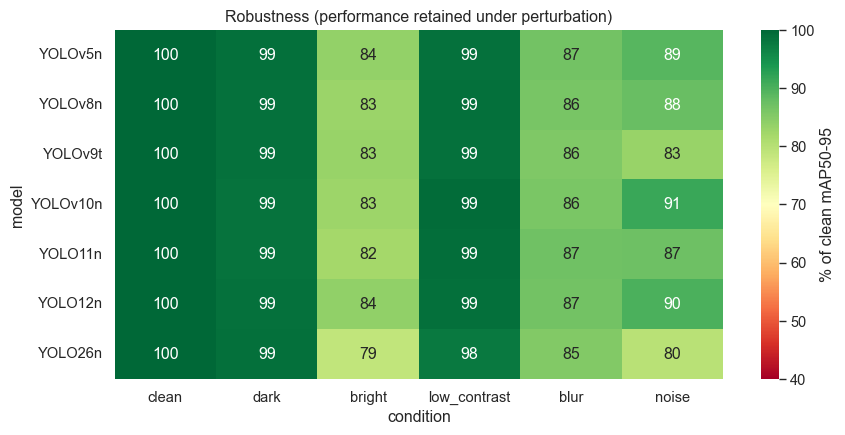

In [27]:
import shutil
from pathlib import Path
import re
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import gc
from ultralytics import YOLO

def p_dark(im):
  return np.clip(im.astype(np.float32) * 0.4, 0, 255).astype(np.uint8)


def p_bright(im):
  return np.clip(im.astype(np.float32) * 1.7 + 20, 0, 255).astype(np.uint8)


def p_lowcon(im):
  return np.clip((im.astype(np.float32) - 128) * 0.5 + 128, 0, 255).astype(
      np.uint8
  )


def p_blur(im):
  return cv2.GaussianBlur(im, (0, 0), sigmaX=4)


def p_noise(im):
  return np.clip(
      im.astype(np.float32) + np.random.RandomState(0).normal(0, 25, im.shape),
      0,
      255,
  ).astype(np.uint8)


PERT = {
    "clean": None,
    "dark": p_dark,
    "bright": p_bright,
    "low_contrast": p_lowcon,
    "blur": p_blur,
    "noise": p_noise,
}

PDIR = WORK / "perturbed"
for pn, fn in PERT.items():
  if fn is None:
    continue
  di, dl = PDIR / pn / "images", PDIR / pn / "labels"
  if di.exists():
    continue
  di.mkdir(parents=True)
  dl.mkdir(parents=True)
  for p in (SPLIT_DIR["test"] / "images").iterdir():
    if p.suffix.lower() not in IMG_EXT:
      continue
    cv2.imwrite(
        str(di / (p.stem + ".jpg")),
        fn(cv2.imread(str(p))),
        [cv2.IMWRITE_JPEG_QUALITY, 95],
    )
    lf = SPLIT_DIR["test"] / "labels" / (p.stem + ".txt")
    if lf.exists():
      shutil.copy(lf, dl / lf.name)
  yaml.safe_dump(
      dict(
          path=str((PDIR / pn).resolve()),
          train="images",
          val="images",
          test="images",
          nc=NC,
          names={i: n for i, n in enumerate(CLASS_NAMES)},
      ),
      open(PDIR / f"{pn}.yaml", "w"),
  )

# Show one example of each perturbation
ex = cv2.imread(str(pick[0]))
fig, axs = plt.subplots(1, len(PERT), figsize=(4 * len(PERT), 3.5))
for a, (pn, fn) in zip(axs, PERT.items()):
  a.imshow(cv2.cvtColor(ex if fn is None else fn(ex), cv2.COLOR_BGR2RGB))
  a.set_title(pn)
  a.axis("off")
plt.tight_layout()
plt.savefig(FIGS / "perturbation_examples.png", dpi=200)
plt.show()

rob = []
for name in MODELS:
  # Extract version number (e.g., '11' from 'YOLO11n')
  match = re.search(r"\d+", name)
  if not match:
    continue
  version = match.group()

  # Construct path with lowercase folder name and matching weight file name
  best = Path(
      f"/kaggle/input/models/pushpendrakumarkiet/yolo{version}/pytorch/default/1/best{version}.pt"
  )

  if not best.exists():
    print(f"Skipping: {best} not found.")
    continue

  m = YOLO(str(best))
  for pn in PERT:
    y = YAML if pn == "clean" else PDIR / f"{pn}.yaml"
    r = m.val(
        data=str(y),
        split="test",
        device=DEVICE,
        plots=False,
        verbose=False,
        project=str(EVAL),
        name=f"rob_{name}_{pn}",
        exist_ok=True,
        **EVAL_KW,
    )
    rob.append(
        dict(
            model=name,
            condition=pn,
            mAP50_95=float(r.box.map),
            mAP50=float(r.box.map50),
        )
    )
  del m
  gc.collect()
  torch.cuda.empty_cache()

df_rob = pd.DataFrame(rob)
df_rob.to_csv(RES / "robustness_long.csv", index=False)

rob_tab = (
    df_rob.pivot(index="model", columns="condition", values="mAP50_95")[
        list(PERT)
    ]
    .loc[MEAN.index]
    .copy()
)
rob_rel = rob_tab.div(rob_tab["clean"], axis=0) * 100  # % of clean performance retained
rob_tab["mean_retained_%"] = rob_rel.drop(columns="clean").mean(axis=1)

rob_tab.round(3).to_csv(RES / "table_robustness.csv")
display(rob_tab.round(3))

plt.figure(figsize=(9, 4.5))
sns.heatmap(
    rob_rel,
    annot=True,
    fmt=".0f",
    cmap="RdYlGn",
    vmin=40,
    vmax=100,
    cbar_kws={"label": "% of clean mAP50-95"},
)
plt.title("Robustness (performance retained under perturbation)")
plt.tight_layout()
plt.savefig(FIGS / "robustness_heatmap.png", dpi=300)
plt.show()

## 16. Export everything (tables, figures, best weights, config) into one zip

In [28]:
import shutil
from pathlib import Path
import re

# Extract the version number of the best model (e.g., '11' from 'YOLO11n')
best_model = S.index[0]
match = re.search(r"\d+", best_model)
if match:
  version = match.group()
  best_weight_path = Path(
      f"/kaggle/input/models/pushpendrakumarkiet/yolo{version}/pytorch/default/1/best{version}.pt"
  )

  # Copy the best model weights to results directory
  if best_weight_path.exists():
    shutil.copy(best_weight_path, RES / f"BEST_{best_model}.pt")
    print(f"Successfully copied best weights for {best_model} to {RES}")
  else:
    print(f"Warning: Best weight file not found at {best_weight_path}")

# Write summary file
with open(RES / "summary.txt", "w") as f:
  f.write(
      f"Recommended model (composite score): {best_model}\n\n{tbl.to_string()}\n\nRanking:\n{S.round(3).to_string()}\n"
  )

# Create archives
shutil.make_archive("weed_experiment_outputs", "zip", root_dir=WORK, base_dir="results")
shutil.make_archive("weed_experiment_figures", "zip", root_dir=WORK, base_dir="figs")

print(
    "Saved: weed_experiment_outputs.zip (CSV/LaTeX tables + best weights) and"
    " weed_experiment_figures.zip (300-dpi figures)"
)
print(open(RES / "summary.txt").read())

Successfully copied best weights for YOLOv9t to weed_exp/results
Saved: weed_experiment_outputs.zip (CSV/LaTeX tables + best weights) and weed_experiment_figures.zip (300-dpi figures)
Recommended model (composite score): YOLOv9t

         Params (M) GFLOPs Size (MB)      P      R     F1 mAP@0.5 mAP@0.5:0.95 CPU ms CPU FPS GPU ms GPU FPS Train (min)
model                                                                                                                   
YOLOv5n        2.64    0.0       5.5  0.918  0.899  0.908   0.944        0.825   75.6    13.2    8.1     124         nan
YOLOv8n        3.14    0.0       6.5  0.912  0.914  0.913   0.949        0.831   78.9    12.7    7.4     136         nan
YOLOv9t        2.11    0.0       4.9  0.926  0.902  0.914   0.953        0.839  112.2     8.9   17.2      58         nan
YOLOv10n       2.74    0.0       5.8  0.928  0.887  0.907   0.947        0.829   77.3    12.9    8.6     116         nan
YOLO11n        2.61    0.0       5.5  0.932 

## Mapping outputs → paper sections
| Paper section | Source |
|---|---|
| Dataset description | `dataset_summary.csv`, `dataset_class_distribution.csv`, `dataset_object_sizes.csv`, `dataset_analysis.png`, `dataset_samples.png` |
| Experimental setup | `experiment_config.json` (hyper-parameters, hardware, versions) |
| Main comparison | `table_main_results.tex`, `accuracy_bars.png`, `pareto.png` |
| Convergence | `training_curves.png` |
| Per-class / error analysis | `table_per_class_AP50_95.csv`, `per_class_ap.png`, `confusion_matrices_all.png` |
| Model selection | `table_ranking.csv` (4 weightings), `ranking_criteria.png` |
| Field robustness | `table_robustness.csv`, `robustness_heatmap.png`, `perturbation_examples.png` |
| Qualitative results | `qualitative_predictions.png` |